# RRAM 모델 1단계 — 파이썬 레퍼런스 (unipolar, 2차원)

`rram_model.py`를 검증하고 2단계용 golden CSV를 만든다. 가정 목록은 `../ASSUMPTIONS.md`.

- RESET: Russo et al., TED 56(2) 193–200 (2009) [R] 식 (1)–(5), Table I — 2차원 원통 좌표에서 전위·열을 풀고 CF 경계가 열 용해로 줄어든다
- SET: DATE 2015 [D] 식 (2)의 측면 성장을 경계의 국소 전계·온도로 적용, compliance 저항으로 전류 제한
- unipolar: 같은 극성, 동작(SET/RESET)으로 식을 나눈다 (A25)

| 절 | 내용 |
|---|---|
| 0 | 설정, 보정 확인 (R_dom, Rth) |
| 1 | RESET 재현: [R] Fig. 3 (I-V, R-V), Fig. 2 (온도 분포), Fig. 4 (T-V) |
| 2 | 램프 속도 의존성: [R] Fig. 5 |
| 3 | 격자 수렴 |
| 4 | 전체 unipolar 사이클 (RESET → SET), compliance 의존성, 전류 제한(CC) 모드, TiN 전극층 |
| 5 | 펄스 SET / RESET |
| 6 | 읽기 저항, 고정 상태 모드 |
| 7 | 변동성 (사이클 간) |
| 7b | 소자 간 몬테카를로 (필라멘트 개수·두께·갭 무작위) |
| 8 | golden CSV 저장 |

In [1]:
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import rram_model as rm

P = rm.DEFAULT
GS = rm.DEFAULT_GRID
GOLDEN = Path("golden")
GOLDEN.mkdir(exist_ok=True)
for old in GOLDEN.glob("*.csv"):
	old.unlink()	# bipolar 시절 golden 제거
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
g = rm.make_grid(P, GS)
print(f"격자: nz = {len(g.zc)}, nr = {len(g.rc)}, R_dom = {P.R_dom*1e9:.1f} nm, N = {P.N}")

격자: nz = 40, nr = 14, R_dom = 53.3 nm, N = 1


## 0. 보정 확인

계산 영역 반경 `R_dom`은 논문에 없다. [R]은 κ_ox를 측정 열저항에 맞췄다고만 한다. 여기서는 κ_ox를 Table I 값 그대로 두고, [R] Fig. 4의 B점(0.78 V에서 T_max ≈ T_crit ≈ 530 K)에 맞도록 `R_dom`을 정했다 (A31).

In [2]:
rb_lrs = np.full(len(g.zc), P.phi0 / 2)
fs = rm.FieldSolver(g, P, rb_lrs)
f078 = fs.solve(0.78)
fs0 = rm.FieldSolver(g, replace(P, alpha_T=0.0), rb_lrs)
f01 = fs0.solve(0.1)
print(f"T_max(0.78 V) = {f078.T.max():.0f} K  (목표 530 K)")
print(f"등가 열저항 Rth = {(f01.T.max() - P.T0) / f01.P:.3g} K/W  ([C] 측정 평균 6.8e4 K/W)")
print(f"LRS 저항 (0.1 V, R_L 포함) = {rm.read_resistance(P.phi0 / 2):.0f} Ω  (CF 단독 계산 {P.rho_cf * P.L0 / (np.pi * P.phi0**2 / 4):.0f} Ω)")

T_max(0.78 V) = 530 K  (목표 530 K)
등가 열저항 Rth = 1.16e+05 K/W  ([C] 측정 평균 6.8e4 K/W)
LRS 저항 (0.1 V, R_L 포함) = 279 Ω  (CF 단독 계산 258 Ω)


## 1. RESET 재현 — [R] Fig. 2, 3, 4

포밍된 LRS(지름 80 nm)에서 4 V/s로 0 → 1.6 → 0 V. compliance 없음.

In [3]:
t_ramp = 1.6 / 4.0
wf_reset = rm.Waveform(lambda t: 1.6 * min(t / t_ramp, 2 - t / t_ramp), lambda t: "reset", 2 * t_ramp, np.array([0, t_ramp, 2 * t_ramp]))
t0 = time.time()
res_reset = rm.simulate(wf_reset, n_snap=0)
vr, ir = rm.reset_point(res_reset)
print(f"{time.time() - t0:.0f} s, {res_reset.info['steps']} 스텝")
print(f"V_reset = {vr:.3f} V, I_reset = {ir*1e3:.2f} mA, T_max = {res_reset.T.max():.0f} K")
R_hrs = rm.read_resistance(res_reset.rb_end)
print(f"R: LRS {rm.read_resistance(P.phi0/2):.0f} Ω → HRS {R_hrs:.3g} Ω, 가장 가는 곳 반경 {res_reset.rb_end.min()*1e9:.1f} nm")

15 s, 340 스텝
V_reset = 1.140 V, I_reset = 2.87 mA, T_max = 831 K
R: LRS 279 Ω → HRS 6.95e+03 Ω, 가장 가는 곳 반경 2.0 nm


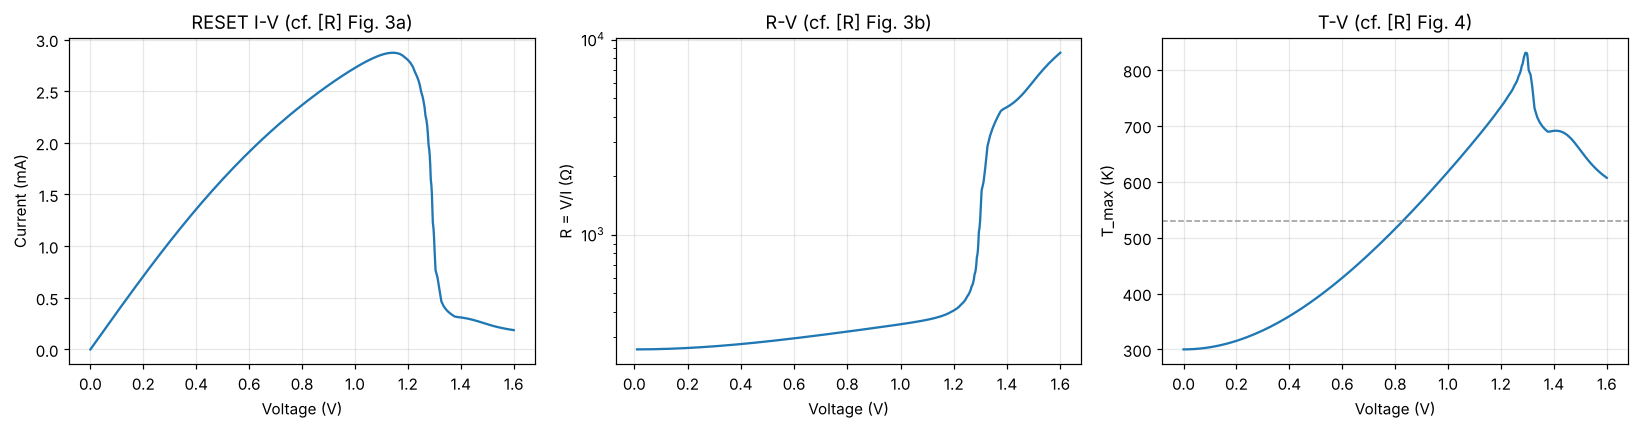

In [4]:
up = res_reset.t <= t_ramp
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(res_reset.v_app[up], res_reset.i[up] * 1e3)
ax[0].set(xlabel="Voltage (V)", ylabel="Current (mA)", title="RESET I-V (cf. [R] Fig. 3a)")
R = res_reset.v_cell[up] / np.where(res_reset.i[up] == 0, np.nan, res_reset.i[up])
ax[1].semilogy(res_reset.v_app[up][1:], R[1:])
ax[1].set(xlabel="Voltage (V)", ylabel="R = V/I (Ω)", title="R-V (cf. [R] Fig. 3b)")
ax[2].plot(res_reset.v_app[up], res_reset.T[up])
ax[2].axhline(530, color="0.6", ls="--", lw=1)
ax[2].set(xlabel="Voltage (V)", ylabel="T_max (K)", title="T-V (cf. [R] Fig. 4)")
plt.tight_layout()

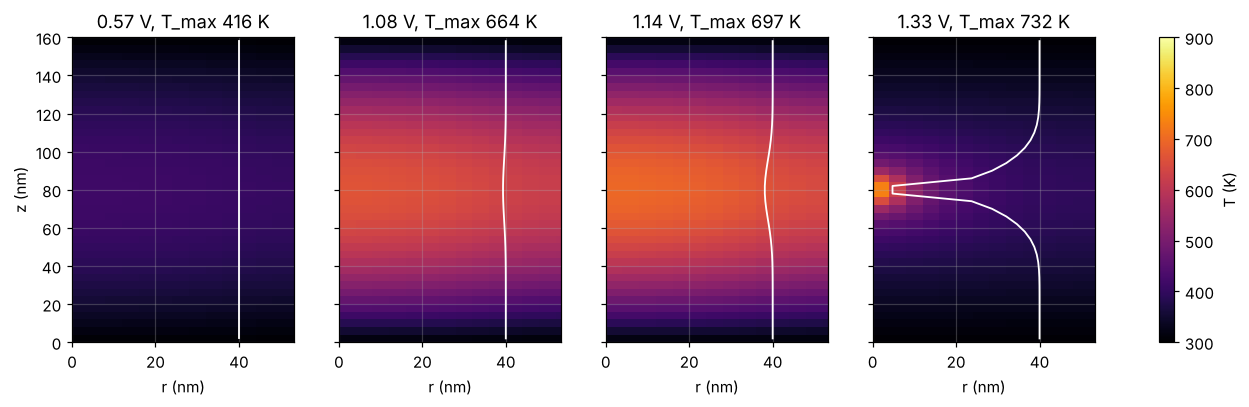

In [5]:
# 온도 분포 스냅숏: 전류 최고점 전후 네 시점 (cf. [R] Fig. 2)
k_peak = int(np.argmax(np.abs(res_reset.i[up])))
v_marks = [0.5 * res_reset.v_app[k_peak], 0.95 * res_reset.v_app[k_peak], res_reset.v_app[k_peak], None]
t_marks = [float(np.interp(v, res_reset.v_app[up], res_reset.t[up])) for v in v_marks[:3]]
# 전류가 최고점 이후 처음으로 최고점의 20% 아래로 떨어진 시점 (최고점 이전의 0 A 구간은 제외)
after = np.abs(res_reset.i[up][k_peak:]) < 0.2 * abs(ir)
t_after = res_reset.t[up][k_peak + int(np.argmax(after))] if np.any(after) else res_reset.t[up][-1]
t_marks.append(float(t_after))
wf_cut = lambda tc: rm.Waveform(wf_reset.v, wf_reset.op, tc, np.array([0, min(t_ramp, tc), tc]))
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for a, tc in zip(ax, t_marks):
	r = rm.simulate(wf_cut(tc), n_snap=2)
	_, va, rb, T = r.snapshots[-1]
	im = a.pcolormesh(g.r_faces * 1e9, g.z_faces * 1e9, T, shading="flat", cmap="inferno", vmin=300, vmax=max(900, T.max()))
	a.plot(rb * 1e9, g.zc * 1e9, color="w", lw=1.2)
	a.set(xlabel="r (nm)", title=f"{va:.2f} V, T_max {T.max():.0f} K")
ax[0].set_ylabel("z (nm)")
fig.colorbar(im, ax=ax, label="T (K)")

**확인:** 전류는 최고점에 이른 뒤 좁은 전압 범위에서 무너지고(급격한 RESET), 저항은 두 자릿수 가까이 오른다. CF는 가장 뜨거운 가운데에서 먼저 가늘어진다. [R] Fig. 2–4와 정성적으로 같다. V_reset은 논문(약 0.85 V)보다 높게 나온다 (A31 참고).

## 2. 램프 속도 의존성 — [R] Fig. 5

  0.4 V/s: V_reset 1.020 V, I_reset 2.70 mA


    4 V/s: V_reset 1.140 V, I_reset 2.87 mA


   40 V/s: V_reset 1.280 V, I_reset 3.05 mA


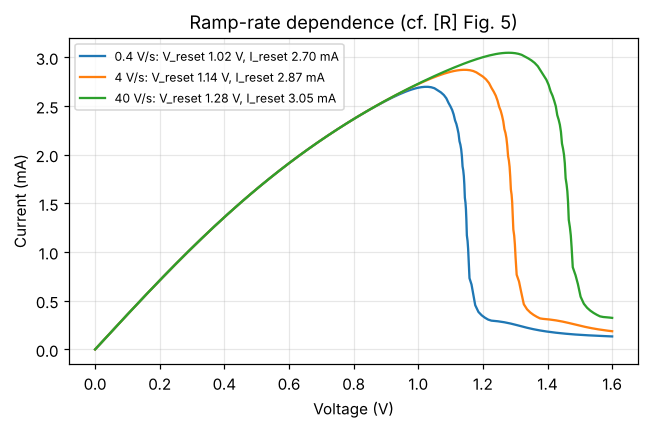

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ramp_results = {}
for k, rate in enumerate([0.4, 4.0, 40.0]):
	tr = 1.6 / rate
	wf = rm.Waveform(lambda t, tr=tr: 1.6 * min(t / tr, 2 - t / tr), lambda t: "reset", 2 * tr, np.array([0, tr, 2 * tr]))
	r = rm.simulate(wf)
	ramp_results[rate] = r
	vr_k, ir_k = rm.reset_point(r)
	upk = r.t <= tr
	ax.plot(r.v_app[upk], r.i[upk] * 1e3, color=f"C{k}", label=f"{rate:g} V/s: V_reset {vr_k:.2f} V, I_reset {ir_k*1e3:.2f} mA")
	print(f"{rate:5g} V/s: V_reset {vr_k:.3f} V, I_reset {ir_k*1e3:.2f} mA")
ax.set(xlabel="Voltage (V)", ylabel="Current (mA)", title="Ramp-rate dependence (cf. [R] Fig. 5)")
ax.legend(fontsize=8)
plt.tight_layout()

## 3. 격자 수렴

V_reset은 격자에 거의 무관하다. 전류가 무너지는 폭과 최종 HRS는 격자가 촘촘할수록 더 급격해지고 커진다 (끊어지는 구간이 한 칸 크기로 정해지기 때문, A35). 기본 격자(4 nm, 40칸)는 브라우저 계산 시간을 고려한 값이다.

In [7]:
for gs_k in [rm.GridSpec(dr_fine=4e-9, nz=40), rm.GridSpec(dr_fine=2e-9, nz=80)]:
	t0 = time.time()
	r = rm.simulate(wf_reset, gs=gs_k)
	vr_k, ir_k = rm.reset_point(r)
	i_up = np.abs(r.i[r.t <= t_ramp]); v_up = r.v_app[r.t <= t_ramp]
	kp = int(np.argmax(i_up)); j10 = kp + int(np.argmax(i_up[kp:] < 0.1 * i_up[kp]))
	print(f"dr {gs_k.dr_fine*1e9:.0f} nm, nz {gs_k.nz}: V_reset {vr_k:.3f} V, 전류 10%까지 {1e3*(v_up[j10]-v_up[kp]):.0f} mV, "
		f"HRS {rm.read_resistance(r.rb_end, gs=gs_k):.3g} Ω  [{time.time()-t0:.0f} s]")

dr 4 nm, nz 40: V_reset 1.140 V, 전류 10%까지 307 mV, HRS 6.95e+03 Ω  [15 s]


dr 2 nm, nz 80: V_reset 1.140 V, 전류 10%까지 164 mV, HRS 1.52e+04 Ω  [60 s]


## 4. 전체 unipolar 사이클

0 → 1.6 V (RESET, compliance 없음) → 0 → 4 V (SET, R_s 직렬) → 0, 구간당 0.25 s. 같은 극성으로 RESET과 SET을 모두 한다.

82 s, 1138 스텝
V_reset 1.17 V (I_reset 2.91 mA), V_set 1.82 V, SET 후 R 227 Ω


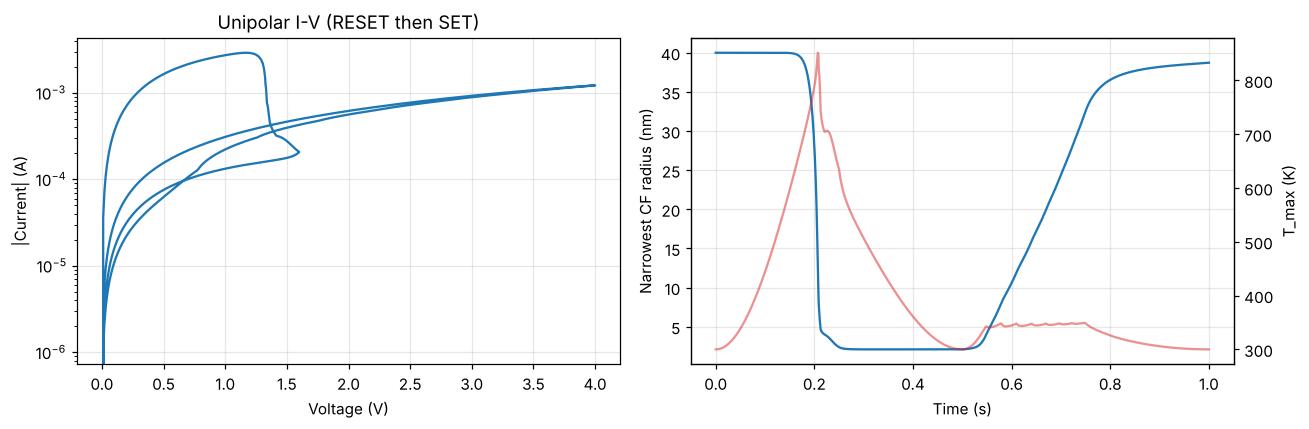

In [8]:
wf_cycle = rm.sweep_waveform(1.6, 4.0, 0.25)
t0 = time.time()
cyc = rm.simulate(wf_cycle)
vr_c, ir_c = rm.reset_point(cyc)
vs_c = rm.set_point(cyc)
print(f"{time.time()-t0:.0f} s, {cyc.info['steps']} 스텝")
print(f"V_reset {vr_c:.2f} V (I_reset {ir_c*1e3:.2f} mA), V_set {vs_c:.2f} V, SET 후 R {rm.read_resistance(cyc.rb_end):.0f} Ω")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(cyc.v_app, np.abs(cyc.i), lw=1.5)
ax[0].set(xlabel="Voltage (V)", ylabel="|Current| (A)", title="Unipolar I-V (RESET then SET)")
ax[1].plot(cyc.t, cyc.r_min * 1e9, label="r_min (nm)")
ax[1].set(xlabel="Time (s)", ylabel="Narrowest CF radius (nm)")
ax2 = ax[1].twinx(); ax2.plot(cyc.t, cyc.T, color="C3", alpha=0.5); ax2.set_ylabel("T_max (K)"); ax2.grid(False)
plt.tight_layout()

In [9]:
# compliance 저항에 따른 SET 후 LRS ([R] VI절: 낮은 compliance → 높은 R_set → 낮은 I_reset)
for Rs in [1e3, 3e3, 10e3]:
	r = rm.simulate(wf_cycle, Rs=Rs)
	print(f"R_s = {Rs/1e3:4.0f} kΩ: V_set {rm.set_point(r):.2f} V, SET 후 R {rm.read_resistance(r.rb_end):.0f} Ω, 가장 가는 곳 {r.rb_end.min()*1e9:.1f} nm")

R_s =    1 kΩ: V_set 0.97 V, SET 후 R 181 Ω, 가장 가는 곳 43.6 nm


R_s =    3 kΩ: V_set 1.82 V, SET 후 R 227 Ω, 가장 가는 곳 38.7 nm


R_s =   10 kΩ: V_set 3.61 V, SET 후 R 513 Ω, 가장 가는 곳 14.2 nm


### 4b. 전류 제한(CC) 모드

측정기처럼 SET 동작에서 단자 전류를 I_CC에 고정한다 (A40). 직렬 저항과 달리 CC 구간이 수평선으로 보인다. v_app에는 설정 전압을 기록한다.

I_CC 1 mA: CC 도달 0.55 V (셀 0.48 V), SET 후 R 206 Ω


I_CC 0.3 mA: SET 후 R 464 Ω


I_CC 3.0 mA: SET 후 R 176 Ω


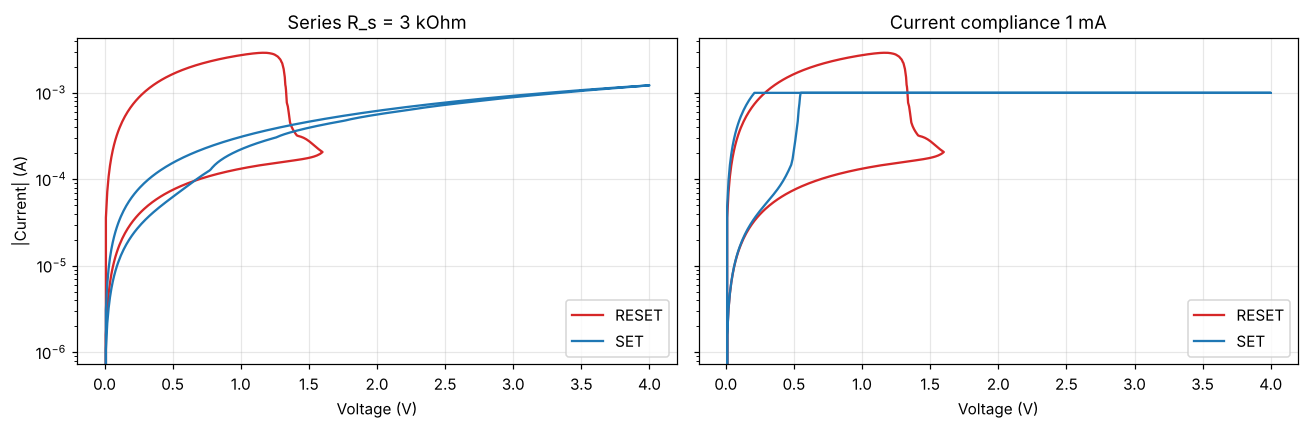

In [10]:
cyc_cc = rm.simulate(wf_cycle, i_cc=1e-3)
half = np.argmax(cyc_cc.t >= 2 * 0.25)
k_cc = half + np.argmax(cyc_cc.i[half:] >= 1e-3 * (1 - 1e-9))
print(f"I_CC 1 mA: CC 도달 {cyc_cc.v_app[k_cc]:.2f} V (셀 {cyc_cc.v_cell[k_cc]:.2f} V), SET 후 R {rm.read_resistance(cyc_cc.rb_end):.0f} Ω")
for icc in [0.3e-3, 3e-3]:
	r = rm.simulate(wf_cycle, i_cc=icc)
	print(f"I_CC {icc*1e3:.1f} mA: SET 후 R {rm.read_resistance(r.rb_end):.0f} Ω")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, r, ttl in [(ax[0], cyc, "Series R_s = 3 kOhm"), (ax[1], cyc_cc, "Current compliance 1 mA")]:
	h = np.argmax(r.t >= 2 * 0.25)
	a.semilogy(r.v_app[:h + 1], np.abs(r.i[:h + 1]), color="C3", label="RESET")
	a.semilogy(r.v_app[h:], np.abs(r.i[h:]), color="C0", label="SET")
	a.set(xlabel="Voltage (V)", title=ttl)
	a.legend()
ax[0].set_ylabel("|Current| (A)")
plt.tight_layout()

### 4c. TiN 전극층 (A41)

전극을 이상적 열 배출로 두지 않고, 두께 t_el인 TiN층(κ 11.9 W/(K·m) [Samani 2013], ρ 125 µΩ·cm [Sun 2018])을 계산 영역에 넣는다. 전극 두께에 따른 열저항과 RESET 전압 변화.

t_el     0 nm: R  286.9 Ω, Rth 1.19e+05 K/W
t_el    20 nm: R  320.3 Ω, Rth 2.01e+05 K/W
t_el    50 nm: R  359.2 Ω, Rth 3.21e+05 K/W
t_el   100 nm: R  413.3 Ω, Rth 5.19e+05 K/W


20 s


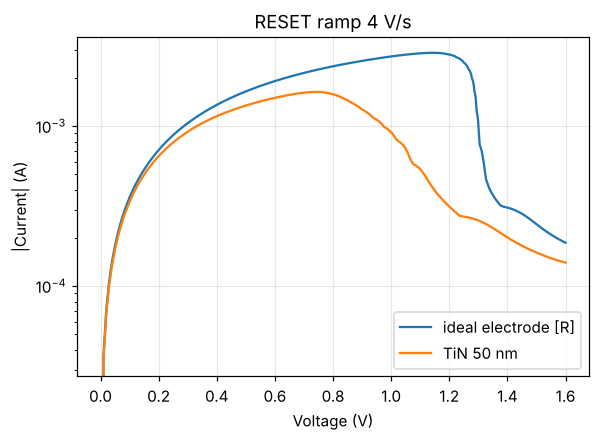

In [11]:
P_tin = replace(P, **rm.TIN_ELECTRODE)
rb40 = np.full(len(g.zc), 40e-9)
for t_el in [0, 20e-9, 50e-9, 100e-9]:
	pp = replace(P_tin, t_el=t_el)
	f = rm.FieldSolver(g, pp, rb40).solve(0.5)
	print(f"t_el {t_el*1e9:5.0f} nm: R {0.5/f.I:6.1f} Ω, Rth {(f.T.max()-pp.T0)/f.P:.3g} K/W")
t0 = time.time()
wf_r = rm.ramp_waveform("reset", 1.6, 4.0)
res_ideal_r = rm.simulate(wf_r, None, P)
res_tin = rm.simulate(wf_r, None, P_tin)
print(f"{time.time()-t0:.0f} s")
fig, ax = plt.subplots(figsize=(6, 4))
for r, lab in [(res_ideal_r, "ideal electrode [R]"), (res_tin, "TiN 50 nm")]:
	ax.semilogy(r.v_app, np.abs(r.i), label=lab)
ax.set(xlabel="Voltage (V)", ylabel="|Current| (A)", title="RESET ramp 4 V/s")
ax.legend()

## 5. 펄스 SET / RESET (C_P 포함)

RESET: LRS에서 3 V / 10 µs (compliance 없음). SET: RESET 스윕 뒤 HRS에서 2.5 V / 1 µs (R_s = 3 kΩ). 상승·하강 10 ns.

RESET 3 V / 10 µs: R → 1.94e+04 Ω, |I|max 4.15 mA, T_max 1962 K, 641 스텝
SET 2.5 V / 1 µs: R → 1.17e+03 Ω, |I|max 0.56 mA, T_max 744 K, 508 스텝


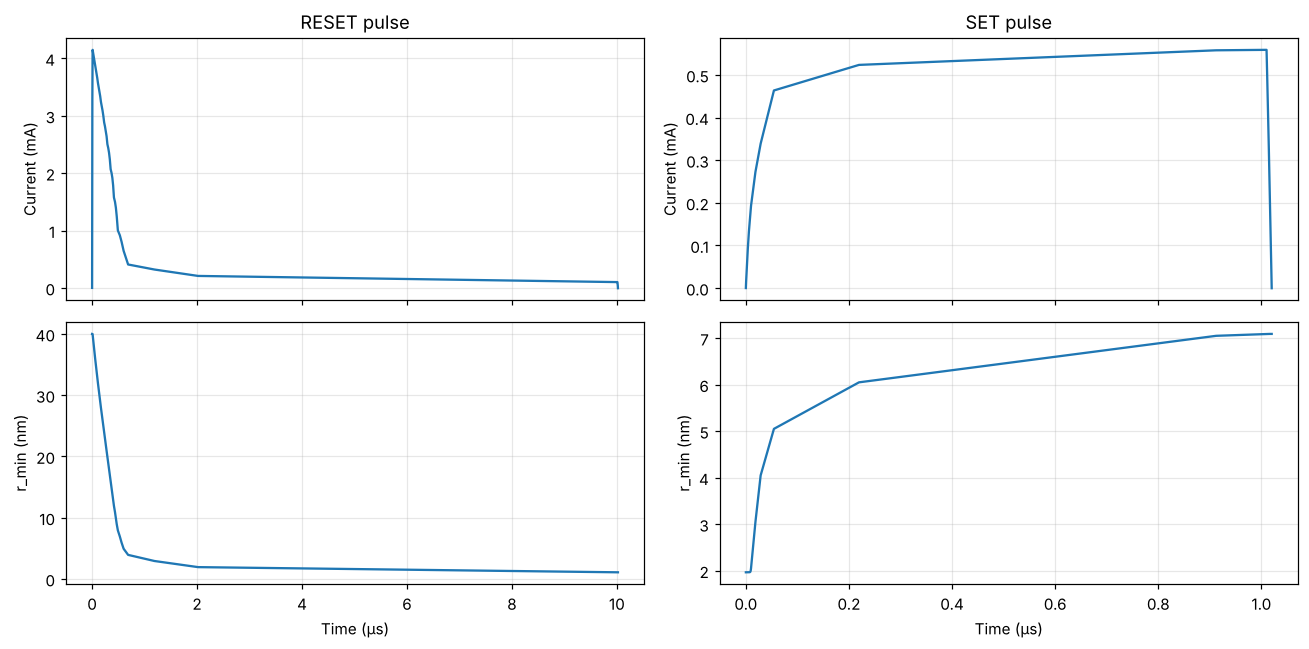

In [12]:
rb_hrs = res_reset.rb_end.copy()
pulse_reset = rm.simulate(rm.pulse_waveform("reset", 3.0, 10e-9, 10e-6), include_cp=True)
pulse_set = rm.simulate(rm.pulse_waveform("set", 2.5, 10e-9, 1e-6), rb0=rb_hrs, include_cp=True)
for name, r in (("RESET 3 V / 10 µs", pulse_reset), ("SET 2.5 V / 1 µs", pulse_set)):
	print(f"{name}: R → {rm.read_resistance(r.rb_end):.3g} Ω, |I|max {np.abs(r.i).max()*1e3:.2f} mA, T_max {r.T.max():.0f} K, {r.info['steps']} 스텝")
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex="col")
for j, (name, r) in enumerate((("RESET", pulse_reset), ("SET", pulse_set))):
	ax[0, j].plot(r.t * 1e6, r.i * 1e3); ax[0, j].set(ylabel="Current (mA)", title=f"{name} pulse")
	ax[1, j].plot(r.t * 1e6, r.r_min * 1e9); ax[1, j].set(xlabel="Time (µs)", ylabel="r_min (nm)")
plt.tight_layout()

## 6. 읽기 저항과 고정 상태 모드

읽기 전압 0.1 V ([C] Fig. 3과 같은 조건). 고정 상태 모드에서는 가운데 잘록 구간의 반경과 길이를 정해 스위칭 없이 I-V를 본다.

잘록 반경 40.0 nm, 길이  0.0 nm → R(0.1 V) = 278.9 Ω
잘록 반경 10.0 nm, 길이  8.0 nm → R(0.1 V) = 742.3 Ω
잘록 반경  4.0 nm, 길이  8.0 nm → R(0.1 V) = 2895 Ω
잘록 반경  2.0 nm, 길이  8.0 nm → R(0.1 V) = 6732 Ω
잘록 반경  2.0 nm, 길이 16.0 nm → R(0.1 V) = 1.184e+04 Ω


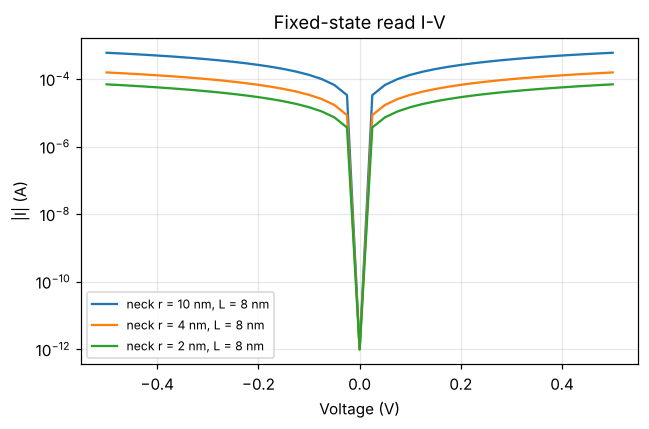

In [13]:
neck_cases = [(40e-9, 0.0), (10e-9, 8e-9), (4e-9, 8e-9), (2e-9, 8e-9), (2e-9, 16e-9)]
read_rows = []
for rn, ln in neck_cases:
	rb = rm.neck_profile(rn, ln) if ln > 0 else np.full(len(g.zc), rn)
	R = rm.read_resistance(rb)
	read_rows.append((rn, ln, R))
	print(f"잘록 반경 {rn*1e9:4.1f} nm, 길이 {ln*1e9:4.1f} nm → R(0.1 V) = {R:.4g} Ω")
v_fix = np.linspace(-0.5, 0.5, 41)
fixed_iv = {}
fig, ax = plt.subplots(figsize=(6, 4))
for k, (rn, ln) in enumerate(neck_cases[1:4]):
	rb = rm.neck_profile(rn, ln)
	i_fix = rm.iv_fixed_state(v_fix, rb)
	fixed_iv[(rn, ln)] = i_fix
	ax.semilogy(v_fix, np.abs(i_fix) + 1e-12, label=f"neck r = {rn*1e9:.0f} nm, L = {ln*1e9:.0f} nm")
ax.set(xlabel="Voltage (V)", ylabel="|I| (A)", title="Fixed-state read I-V")
ax.legend(fontsize=8)
plt.tight_layout()

## 7. 변동성

사이클마다 SET 장벽 Ea와 RESET 장벽 Ed를 정규분포로 다시 뽑는다 ([D] 식 (10),(11), unipolar에서는 RESET 장벽이 Ed, A13). 사이클 하나가 오래 걸려 3사이클만 본다.

In [14]:
rng = np.random.default_rng(2015)
var = rm.Variability()
rb = None
var_rows = []
t0 = time.time()
for c in range(3):
	pc = rm.sample_cycle_params(P, var, rng)
	r = rm.simulate(wf_cycle, rb0=rb, p=pc)
	vr_k, ir_k = rm.reset_point(r)
	var_rows.append((vr_k, ir_k, rm.set_point(r, pc), rm.read_resistance(r.rb_end, p=pc)))
	rb = r.rb_end
	print(f"사이클 {c+1}: V_reset {vr_k:.2f} V, I_reset {ir_k*1e3:.2f} mA, V_set {var_rows[-1][2]:.2f} V, SET 후 R {var_rows[-1][3]:.0f} Ω")
print(f"{time.time()-t0:.0f} s")

사이클 1: V_reset 1.18 V, I_reset 2.92 mA, V_set 1.87 V, SET 후 R 228 Ω


사이클 2: V_reset 1.02 V, I_reset 3.23 mA, V_set 1.70 V, SET 후 R 221 Ω


사이클 3: V_reset 0.98 V, I_reset 3.17 mA, V_set 1.60 V, SET 후 R 218 Ω
242 s


## 7b. 소자 간 몬테카를로 (교수님 요청)

고정 상태에서 소자마다 필라멘트 개수(포아송, 0개 제외), 필라멘트마다 지름·잘록 구간(갭) 반경·길이(로그정규)를 무작위로 뽑는다 (A38, A39). 필라멘트마다 형상이 달라 각각 2차원으로 풀고 병렬로 합친다.

A_cell = 0.01 um2 (mean 1): N 평균 1.64, R 중앙값 1784 Ω, P10–P90 795–4106 Ω, σ(log10 R) 0.28  [9 s]


A_cell = 0.04 um2 (mean 4): N 평균 4.08, R 중앙값 648 Ω, P10–P90 361–1632 Ω, σ(log10 R) 0.27  [20 s]


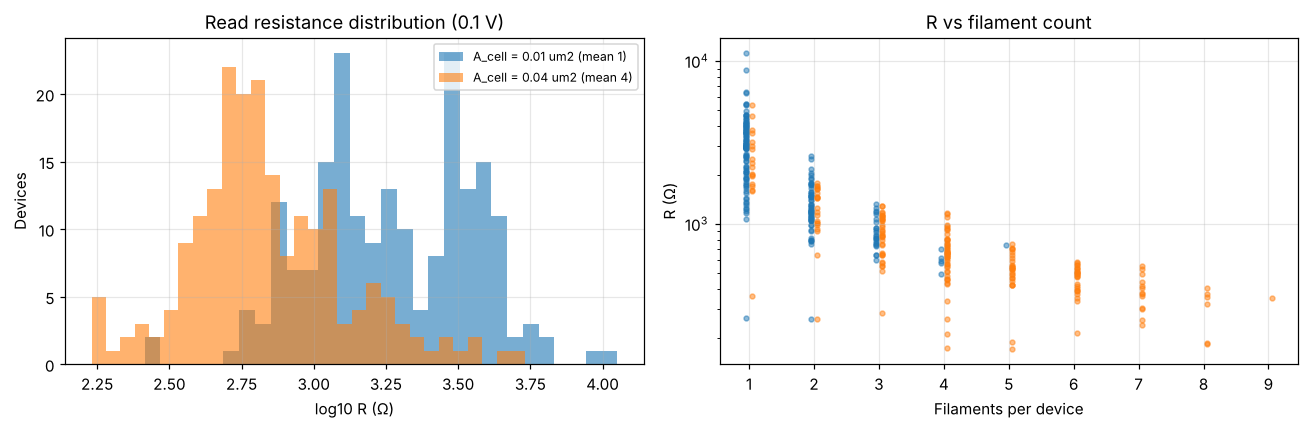

In [15]:
spec = rm.MonteCarloSpec(devices=200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (label, pk) in enumerate((("A_cell = 0.01 um2 (mean 1)", P), ("A_cell = 0.04 um2 (mean 4)", replace(P, A_cell=4e-14)))):
	t0 = time.time()
	R, N, _ = rm.monte_carlo(spec, p=pk, rng=np.random.default_rng(7))
	lg = np.log10(R)
	print(f"{label}: N 평균 {N.mean():.2f}, R 중앙값 {np.median(R):.0f} Ω, P10–P90 {np.percentile(R,10):.0f}–{np.percentile(R,90):.0f} Ω, σ(log10 R) {lg.std():.2f}  [{time.time()-t0:.0f} s]")
	ax[0].hist(lg, bins=30, alpha=0.6, color=f"C{k}", label=label)
	ax[1].scatter(N + 0.1 * (k - 0.5), R, s=10, alpha=0.5, color=f"C{k}", label=label)
ax[0].set(xlabel="log10 R (Ω)", ylabel="Devices", title="Read resistance distribution (0.1 V)")
ax[0].legend(fontsize=8)
ax[1].set(xlabel="Filaments per device", ylabel="R (Ω)", yscale="log", title="R vs filament count")
plt.tight_layout()

## 8. golden CSV 저장 (2단계 정답지)

결정론적 경우만 저장한다. 각 파일 설명은 `golden/README.md`.

In [16]:
hdr = rm.CSV_HEADER
np.savetxt(GOLDEN / "reset_sweep_4Vps.csv", res_reset.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "cycle_sweep.csv", cyc.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "cycle_sweep_cc.csv", cyc_cc.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "reset_ramp_tin.csv", res_tin.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "pulse_reset.csv", pulse_reset.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "pulse_set.csv", pulse_set.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "hrs_profile.csv", np.column_stack([g.zc, rb_hrs]), delimiter=",", header="z_m,rb_m", comments="")
np.savetxt(GOLDEN / "read_resistance.csv", np.array(read_rows), delimiter=",", header="r_neck_m,neck_len_m,R_ohm", comments="")
rows = []
for (rn, ln), i_fix in fixed_iv.items():
	for vk, ik in zip(v_fix, i_fix):
		rows.append((rn, ln, vk, ik))
np.savetxt(GOLDEN / "fixed_state_iv.csv", np.array(rows), delimiter=",", header="r_neck_m,neck_len_m,v_V,i_A", comments="")
# 기본 함수 확인: 정상 상태 전위·온도 한 번 풀기
rows = []
for rn, ln in neck_cases:
	rb = rm.neck_profile(rn, ln) if ln > 0 else np.full(len(g.zc), rn)
	for v in (0.1, 0.5, 1.0):
		fld = rm.FieldSolver(g, P, rb).solve(v)
		rows.append((rn, ln, v, fld.I, fld.T.max(), fld.P))
np.savetxt(GOLDEN / "fields.csv", np.array(rows), delimiter=",", header="r_neck_m,neck_len_m,v_V,i_A,T_max_K,P_W", comments="")
# TiN 전극층 (A41): 셀 면적 두 가지 (전극 옆 범위가 R_dom 근처 / 넓게)
rows = []
for a_cell in (1e-14, 1e-12):
	pp = replace(P_tin, A_cell=a_cell, n_f=1 / a_cell)
	for rn, ln in neck_cases:
		rb = rm.neck_profile(rn, ln, pp) if ln > 0 else np.full(len(g.zc), rn)
		for v in (0.1, 0.5):
			fld = rm.FieldSolver(g, pp, rb).solve(v)
			rows.append((a_cell, rn, ln, v, fld.I, fld.T.max(), fld.P))
np.savetxt(GOLDEN / "fields_tin.csv", np.array(rows), delimiter=",", header="A_cell_m2,r_neck_m,neck_len_m,v_V,i_A,T_max_K,P_W", comments="")
# 소자 간 몬테카를로의 결정론적 부분: 정해진 필라멘트 목록의 소자 읽기 저항
mc_cases = [
	[rm.FilamentGeom(80e-9, 4e-9, 8e-9)],
	[rm.FilamentGeom(80e-9, 40e-9, 0.0), rm.FilamentGeom(60e-9, 2e-9, 12e-9)],
	[rm.FilamentGeom(70e-9, 3e-9, 6e-9), rm.FilamentGeom(90e-9, 5e-9, 10e-9), rm.FilamentGeom(50e-9, 1.5e-9, 16e-9)],
]
rows = []
for c, fil in enumerate(mc_cases):
	for fg in fil:
		rows.append((c, fg.phi, fg.r_neck, fg.neck_len, rm.device_read(fil)))
np.savetxt(GOLDEN / "mc_devices.csv", np.array(rows), delimiter=",", header="case,phi_m,r_neck_m,neck_len_m,R_device_ohm", comments="")
print(sorted(p.name for p in GOLDEN.glob("*.csv")))

['cycle_sweep.csv', 'cycle_sweep_cc.csv', 'fields.csv', 'fields_tin.csv', 'fixed_state_iv.csv', 'hrs_profile.csv', 'mc_devices.csv', 'pulse_reset.csv', 'pulse_set.csv', 'read_resistance.csv', 'reset_ramp_tin.csv', 'reset_sweep_4Vps.csv']
